In [ ]:
!apt-get update
!apt-get install -y tcpdump tshark
!pip install pandas numpy scikit-learn matplotlib seaborn

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:5 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Hit:7 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:8 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Get:9 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [2,955 kB]
Get:10 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:11 http://security.ubuntu.com/ubuntu jammy-security/main amd64 Packages [3,844 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu jammy/main all Packages [9,963 kB]
Get:13 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 Packages [1,622 kB]
Get:14 http://security.ubun

In [ ]:
import os
import time
import subprocess
import socket
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

websites = [
    "https://www.indiatimes.com", "https://www.washingtonpost.com", "https://www.ndtv.com",
    "https://www.cnbc.com", "https://www.timesofindia.com", "https://www.express.co.uk",
    "https://www.rt.com", "https://www.news18.com", "https://www.nypost.com", "https://www.abc.net.au",
    "https://www.bbc.co.uk", "https://www.msn.com", "https://www.cnn.com", "https://www.news.google.com",
    "https://www.dailymail.co.uk", "https://www.nytimes.com", "https://www.theguardian.com",
    "https://www.foxnews.com", "https://www.finance.yahoo.com", "https://www.news.yahoo.com"
]

os.makedirs("csv_captures", exist_ok=True)
# Find local IP to separate Uplink and Downlink traffic later
s = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
s.connect(("8.8.8.8", 80))
local_ip = s.getsockname()[0]
s.close()
print(f"Colab IP is {local_ip}")

# Capture loop for 20 websites, 10 times each
for site in websites:
    app_name = site.split("//")[1].replace("www.", "").split(".")[0]
    print(f"Capturing {app_name}...")

    for i in range(10):
        pcap_file = f"capture.pcap"
        csv_file = f"csv_captures/{app_name}_{i}.csv"

        # Capture HTTPS traffic in the background
        tcpdump_process = subprocess.Popen(["tcpdump", "-i", "eth0", "-w", pcap_file, "tcp port 443"])
        # Waiting for initialization
        time.sleep(1)

        # Curl the website to generate traffic
        subprocess.run(["curl", "-s", "-o", "/dev/null", site])
        # Waiting for it to load
        time.sleep(3)

        tcpdump_process.terminate()
        tcpdump_process.wait()

        # Convert PCAP to CSV using tshark
        tshark_cmd = [
            "tshark", "-r", pcap_file, "-T", "fields",
            "-e", "frame.time_epoch", "-e", "ip.src", "-e", "ip.dst",
            "-e", "tcp.srcport", "-e", "tcp.dstport", "-e", "ip.len", "-e", "tcp.len",
            "-E", "header=y", "-E", "separator=,"
        ]
        with open(csv_file, "w") as outfile:
            subprocess.run(tshark_cmd, stdout=outfile)

print("Dataset generation complete!")


Colab IP is 172.28.0.12
Capturing indiatimes...
Capturing washingtonpost...
Capturing ndtv...
Capturing cnbc...
Capturing timesofindia...
Capturing express...
Capturing rt...
Capturing news18...
Capturing nypost...
Capturing abc...
Capturing bbc...
Capturing msn...
Capturing cnn...
Capturing news...
Capturing dailymail...
Capturing nytimes...
Capturing theguardian...
Capturing foxnews...
Capturing finance...
Capturing news...
Dataset generation complete!


In [ ]:
from os import listdir
from os.path import isfile, join

def extract_biflow_features(df_flow, local_ip, filename):
    features = {}

    # Separate uplink and downlink
    df_up = df_flow[df_flow['ip.src'] == local_ip].copy()
    df_down = df_flow[df_flow['ip.dst'] == local_ip].copy()

    #function to calculate min/max/mean/std
    def get_stats(series, prefix):
        if len(series) == 0 or series.isna().all():
            return {f'min_{prefix}': 0, f'max_{prefix}': 0, f'mean_{prefix}': 0, f'std_{prefix}': 0}
        return {
            f'min_{prefix}': series.min(),
            f'max_{prefix}': series.max(),
            f'mean_{prefix}': series.mean(),
            f'std_{prefix}': series.std() if not pd.isna(series.std()) else 0
        }

    # Extract Packet Sizes
    up_sizes = df_up['ip.len'].astype(float)
    down_sizes = df_down['ip.len'].astype(float)

    features['num_packets_up'] = len(df_up)
    features['num_packets_down'] = len(df_down)
    features['total_bytes_up'] = up_sizes.sum()
    features['total_bytes_down'] = down_sizes.sum()

    features.update(get_stats(up_sizes, 'size_up'))
    features.update(get_stats(down_sizes, 'size_down'))

    # Extract IAT
    up_times = df_up['frame.time_epoch'].astype(float).sort_values()
    down_times = df_down['frame.time_epoch'].astype(float).sort_values()

    up_iat = up_times.diff().iloc[1:]
    down_iat = down_times.diff().iloc[1:]

    features.update(get_stats(up_iat, 'iat_up'))
    features.update(get_stats(down_iat, 'iat_down'))

    # Ground truth application label from filename
    features['app'] = filename.split('_')[0]

    return features

# Process all captured CSVs into a single Dataset DataFrame
path = 'csv_captures'
if os.path.exists(path):
    csv_files = [f for f in listdir(path) if isfile(join(path, f))]
else:
    csv_files = []

dataset_list = []
print(f"Processing {len(csv_files)} capture files...")

for f in csv_files:
    try:
        # Load the CSV
        df = pd.read_csv(join(path, f)).dropna(subset=['ip.src', 'ip.dst'])

        # Extract features
        features = extract_biflow_features(df, local_ip, f)
        dataset_list.append(pd.DataFrame([features]))
    except Exception as e:
        pass

#final dataset and display
if len(dataset_list) > 0:
    dataset = pd.concat(dataset_list, ignore_index=True)
    display(dataset)
else:
    print("Error: No data to display. Please re-run Block 1.")

Processing 190 capture files...


,num_packets_up,num_packets_down,total_bytes_up,total_bytes_down,min_size_up,max_size_up,mean_size_up,std_size_up,min_size_down,max_size_down,...,std_size_down,min_iat_up,max_iat_up,mean_iat_up,std_iat_up,min_iat_down,max_iat_down,mean_iat_down,std_iat_down,app
0,16,18,1646.0,5185.0,40.0,569.0,102.875000,127.449794,52.0,2736.0,...,629.624022,0.000009,0.090980,0.009859,0.022824,0.000000e+00,0.098081,0.008248,0.023546,cnbc
1,107,106,6392.0,1230278.0,40.0,569.0,59.738318,51.281380,52.0,56524.0,...,15394.254005,0.000006,0.095881,0.002279,0.009585,9.536743e-07,0.104170,0.002223,0.010455,news18
2,15,12,1607.0,5386.0,40.0,569.0,107.133333,130.779458,52.0,3386.0,...,937.258365,0.000011,0.077509,0.010083,0.020266,9.536743e-07,0.085052,0.012156,0.025107,ndtv
3,32,28,2490.0,61863.0,40.0,569.0,77.812500,92.212741,52.0,4396.0,...,1583.102166,0.000003,0.086073,0.005781,0.015764,0.000000e+00,0.092897,0.006386,0.018136,msn
4,127,127,7404.0,1586756.0,40.0,569.0,58.299213,46.968803,52.0,28932.0,...,9639.396381,0.000005,0.101456,0.002554,0.011367,0.000000e+00,0.094222,0.002496,0.011299,nytimes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
185,19,13,1839.0,11723.0,52.0,569.0,96.789474,116.662180,52.0,4148.0,...,1238.571567,0.000006,0.080966,0.007068,0.018943,1.907349e-06,0.088072,0.010025,0.024755,news
186,19,13,1841.0,11755.0,52.0,569.0,96.894737,116.682330,52.0,4148.0,...,1238.036359,0.000015,0.079415,0.006908,0.018525,4.601479e-05,0.086360,0.009791,0.024277,finance
187,20,14,1893.0,11809.0,52.0,569.0,94.650000,114.013053,52.0,4148.0,...,1231.745275,0.000009,0.080795,0.006898,0.018468,4.196167e-05,0.088626,0.009478,0.023985,finance
188,16,14,1671.0,11061.0,52.0,569.0,104.437500,126.216200,52.0,4148.0,...,1221.621713,0.000009,0.078896,0.008338,0.020109,9.536743e-07,0.086958,0.009085,0.023643,news


Accuracy for k=1: 70.175%
Accuracy for k=2: 71.930%
Accuracy for k=3: 64.912%
Accuracy for k=4: 66.667%
Accuracy for k=5: 57.895%
Accuracy for k=6: 52.632%
Accuracy for k=7: 54.386%
Accuracy for k=8: 54.386%
Accuracy for k=9: 45.614%
Accuracy for k=10: 49.123%


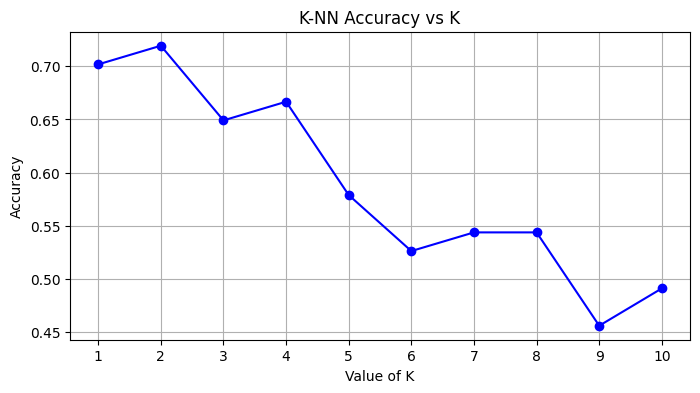

In [ ]:
if 'dataset' in locals() and not dataset.empty:
    # Separate features (X) and target (Y)
    X = dataset.drop(['app'], axis=1).dropna()

    # Encode the string labels (website names) into numerical classes
    le = LabelEncoder()
    Y = le.fit_transform(dataset['app'])
    label_names = le.classes_

    # Split the dataset in train (70%) and test (30%) set
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)

    # Normalization
    scaler = StandardScaler()
    X_train_norm = scaler.fit_transform(X_train)
    X_test_norm = scaler.transform(X_test)

    #Evaluate performance of a k-NN approach for k=1..10
    accuracies = []
    k_range = range(1, 11)

    for k in k_range:
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_norm, y_train)
        y_pred = knn.predict(X_test_norm)
        accuracies.append(accuracy_score(y_test, y_pred))
        # Calculate and store accuracy and print it
        acc = accuracy_score(y_test, y_pred)
        print(f"Accuracy for k={k}: {acc*100:.3f}%")

    #Plot the accuracy-vs-K relation on a figure
    fig = plt.figure(figsize=(8, 4))
    plt.plot(k_range, accuracies, 'b', marker='o')
    plt.xlabel('Value of K')
    plt.ylabel('Accuracy')
    plt.title('K-NN Accuracy vs K')
    plt.xticks(k_range)
    plt.grid(visible=True)
    plt.show()
else:
    print("Dataset not found. Please run Block 2 first.")

Best K found: 2 with accuracy 71.930%


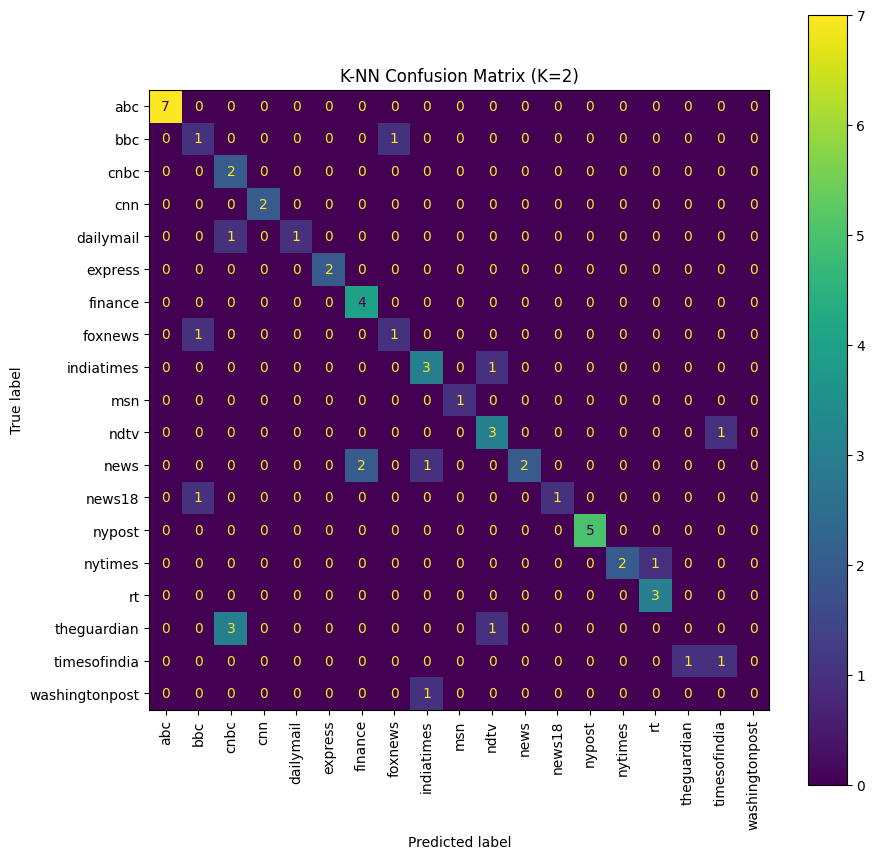

In [ ]:
# Find the best K based on the accuracies
best_k = accuracies.index(max(accuracies)) + 1
print(f"Best K found: {best_k} with accuracy {max(accuracies)*100:.3f}%")

# Train final k-NN model with the best K
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_norm, y_train)
y_pred_best = best_knn.predict(X_test_norm)

# Generate and plot the Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 10))
cm = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, xticks_rotation='vertical', cmap='viridis')
plt.title(f'K-NN Confusion Matrix (K={best_k})')
plt.show()

In [ ]:
print("--- Starting Task 6: 'Day 2' Test Set Generation ---")
os.makedirs("csv_captures_day2", exist_ok=True)

# 1. Capture the new test set (3 times per website)
print("Capturing 3 traces per website...")
for site in websites:
    app_name = site.split("//")[1].replace("www.", "").split(".")[0]

    for i in range(3):
        pcap_file = "capture_day2.pcap"
        csv_file = f"csv_captures_day2/{app_name}_{i}.csv"

        tcpdump_process = subprocess.Popen(["tcpdump", "-i", "eth0", "-w", pcap_file, "tcp port 443"])
        time.sleep(1)
        subprocess.run(["curl", "-s", "-o", "/dev/null", site])
        time.sleep(3)
        tcpdump_process.terminate()
        tcpdump_process.wait()

        tshark_cmd = [
            "tshark", "-r", pcap_file, "-T", "fields",
            "-e", "frame.time_epoch", "-e", "ip.src", "-e", "ip.dst",
            "-e", "tcp.srcport", "-e", "tcp.dstport", "-e", "ip.len", "-e", "tcp.len",
            "-E", "header=y", "-E", "separator=,"
        ]
        with open(csv_file, "w") as outfile:
            subprocess.run(tshark_cmd, stdout=outfile)

# 2. Process the new captures into features
print("\nExtracting features from new test set...")
path_day2 = 'csv_captures_day2'
csv_files_day2 = [f for f in os.listdir(path_day2) if os.path.isfile(os.path.join(path_day2, f))]

dataset_day2_list = []
for f in csv_files_day2:
    try:
        df = pd.read_csv(os.path.join(path_day2, f)).dropna(subset=['ip.src', 'ip.dst'])
        features = extract_biflow_features(df, local_ip, f)
        dataset_day2_list.append(pd.DataFrame([features]))
    except Exception as e:
        pass

if len(dataset_day2_list) > 0:
    dataset_day2 = pd.concat(dataset_day2_list, ignore_index=True).dropna()

    # 3. Evaluate using the OLD training set's models
    X_day2 = dataset_day2.drop(['app'], axis=1)

    y_day2_true = le.transform(dataset_day2['app'])
    X_day2_norm = scaler.transform(X_day2)

    # Predict using the best K-NN model trained
    y_pred_day2 = best_knn.predict(X_day2_norm)
    day2_acc = accuracy_score(y_day2_true, y_pred_day2) * 100

    print("\n--- TASK 6 RESULTS ---")
    print(f"Original Training Best Accuracy: {max(accuracies)*100:.2f}%")
    print(f"New 'Day 2' Test Set Accuracy:   {day2_acc:.2f}%")
else:
    print("Error: No data captured for the new test set.")

--- Starting Task 6: 'Day 2' Test Set Generation ---
Capturing 3 traces per website...

Extracting features from new test set...

--- TASK 6 RESULTS ---
Original Training Best Accuracy: 71.93%
New 'Day 2' Test Set Accuracy:   64.91%


Conclusion: \
The goal of this task is to see how well the model holds up over time. \
As we can see, the accuracy dropped 7.02% which perfectly shows even in a short amount of time, these news websites are constantly updating; they load different ads,or new breaking news bannersand swap background script. Since our k-NN model relies on the exact "shape" of the traffic, these minor changes are enough to confuse the classifier. \
The assignment suggests waiting  a full day to capture the test set, but due to shortage of time and google colab's technical limitations the new test set captured a few hours after the first one.\
If we had waited a full 24 hours, the accuracy drop would likely be larger.





Extracting CUMUL features (M=20)...
Standard Features Best Accuracy:  71.93%
Panchenko Features Best Accuracy: 85.96% (at K=4)
Improvement using Panchenko:      +14.04%!


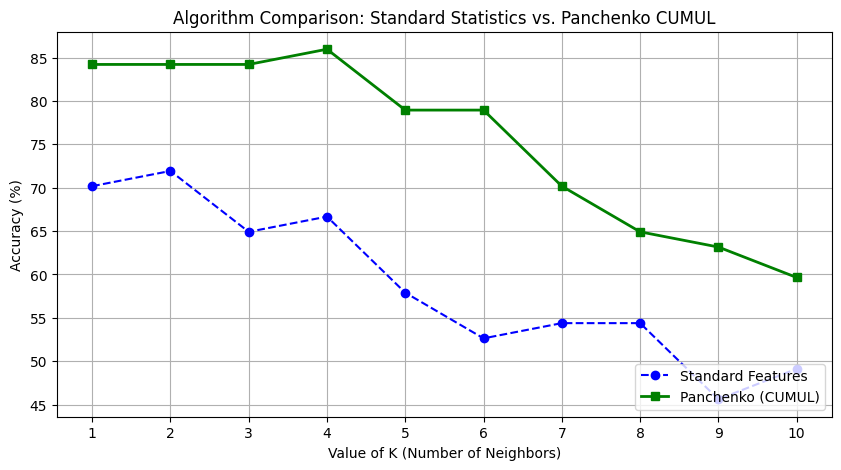

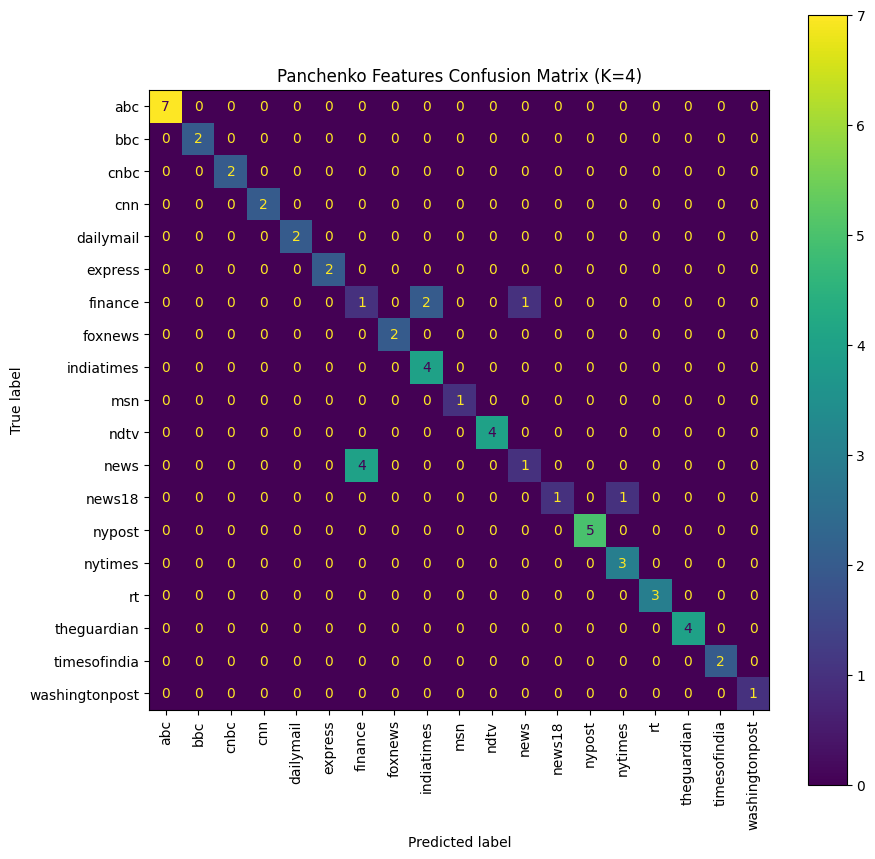

In [ ]:
def extract_panchenko_features(df_flow, local_ip, filename, M=20):
    # 1. Remove TCP ACKs
    df_filtered = df_flow[df_flow['tcp.len'].fillna(0).astype(float) > 0].copy()

    if len(df_filtered) < 2:
        return None

    directions = np.where(df_filtered['ip.dst'] == local_ip, 1, -1)
    sizes = df_filtered['ip.len'].astype(float).values
    directed_sizes = sizes * directions

    #Produce cumulative trace C
    C = np.cumsum(directed_sizes)

    # Create an artificial X axis
    x_original = np.linspace(0, 1, len(C))
    # Create the M equidistant points
    x_sampled = np.linspace(0, 1, M)

    # Interpolate to get exactly 20 features
    sampled_C = np.interp(x_sampled, x_original, C)

    # Build feature dictionary
    features = {f'c_{i}': val for i, val in enumerate(sampled_C)}
    features['app'] = filename.split('_')[0]

    return features

# Re-process the original CSV
print("Extracting features (M=20)...")
panchenko_dataset_list = []

for f in csv_files:
    try:
        df = pd.read_csv(os.path.join(path, f)).dropna(subset=['ip.src', 'ip.dst'])
        features = extract_panchenko_features(df, local_ip, f, M=20)
        if features is not None:
            panchenko_dataset_list.append(pd.DataFrame([features]))
    except Exception as e:
        pass

if len(panchenko_dataset_list) > 0:
    dataset_panchenko = pd.concat(panchenko_dataset_list, ignore_index=True)

    # Separate features and target
    X_p = dataset_panchenko.drop(['app'], axis=1)
    le_p = LabelEncoder()
    Y_p = le_p.fit_transform(dataset_panchenko['app'])

    # Train/Test Split (70/30)
    Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_p, Y_p, test_size=0.3, random_state=42)

    # Normalize
    scaler_p = StandardScaler()
    Xp_train_norm = scaler_p.fit_transform(Xp_train)
    Xp_test_norm = scaler_p.transform(Xp_test)

    # Evaluate k-NN
    accuracies_p = []
    k_range = range(1, 11)
    for k in k_range:
        knn_p = KNeighborsClassifier(n_neighbors=k)
        knn_p.fit(Xp_train_norm, yp_train)
        accuracies_p.append(accuracy_score(yp_test, knn_p.predict(Xp_test_norm)))

    best_k_p = accuracies_p.index(max(accuracies_p)) + 1
    best_acc_p = max(accuracies_p) * 100

    # Grab the old accuracy
    old_best_acc = max(accuracies) * 100 if 'accuracies' in locals() else 71.93


    print(f"Standard Features Best Accuracy:  {old_best_acc:.2f}%")
    print(f"Panchenko Features Best Accuracy: {best_acc_p:.2f}% (at K={best_k_p})")

    if best_acc_p > old_best_acc:
        print(f"Improvement using Panchenko:      +{best_acc_p - old_best_acc:.2f}%!")
    else:
        print(f"Difference:                       {best_acc_p - old_best_acc:.2f}%")
else:
    print("Error processing Panchenko dataset.")


import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Plot: standard vs Panchenko accuracy
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 5))


acc_percent_standard = [acc * 100 for acc in accuracies]
acc_percent_panchenko = [acc * 100 for acc in accuracies_p]

# Plot both lines
plt.plot(k_range, acc_percent_standard, color='blue', marker='o', linestyle='dashed', label='Standard Features')
plt.plot(k_range, acc_percent_panchenko, color='green', marker='s', linewidth=2, label='Panchenko')

plt.xlabel('Value of K (Number of Neighbors)')
plt.ylabel('Accuracy (%)')
plt.title('Algorithm Comparison: Standard Statistics vs. Panchenko ')
plt.xticks(k_range)
plt.legend(loc='lower right')
plt.grid(visible=True)
plt.show()

# confusion martrix

best_knn_p = KNeighborsClassifier(n_neighbors=best_k_p)
best_knn_p.fit(Xp_train_norm, yp_train)

yp_pred_best = best_knn_p.predict(Xp_test_norm)

fig, ax = plt.subplots(figsize=(10, 10))
cm_p = confusion_matrix(yp_test, yp_pred_best)

disp_p = ConfusionMatrixDisplay(confusion_matrix=cm_p, display_labels=le_p.classes_)
disp_p.plot(ax=ax, xticks_rotation='vertical', cmap='viridis')

plt.title(f'Panchenko Features Confusion Matrix (K={best_k_p})')
plt.show()

Observations and conclusion: \
By implementing the Panchenko mothod, the model's accuracy improvewd over 14%(using cumulative features at K=4). \
Also the confusion matrix became cleaner, with a much stronger diagonal correct prediction. \
This massive jump (14%), shows that, the sequence and timing of packets contain far more identifiable finger printing data than statistical averages

In [ ]:
!zip -r my_dataset_submission.zip csv_captures/ csv_captures_day2/ *.pcap

  adding: csv_captures/ (stored 0%)
  adding: csv_captures/cnbc_5.csv (deflated 85%)
  adding: csv_captures/news18_9.csv (deflated 90%)
  adding: csv_captures/ndtv_5.csv (deflated 83%)
  adding: csv_captures/msn_9.csv (deflated 87%)
  adding: csv_captures/nytimes_6.csv (deflated 90%)
  adding: csv_captures/nypost_1.csv (deflated 81%)
  adding: csv_captures/washingtonpost_4.csv (deflated 83%)
  adding: csv_captures/ndtv_4.csv (deflated 84%)
  adding: csv_captures/indiatimes_7.csv (deflated 85%)
  adding: csv_captures/dailymail_3.csv (deflated 84%)
  adding: csv_captures/bbc_7.csv (deflated 90%)
  adding: csv_captures/nypost_0.csv (deflated 83%)
  adding: csv_captures/theguardian_9.csv (deflated 84%)
  adding: csv_captures/cnn_1.csv (deflated 91%)
  adding: csv_captures/dailymail_1.csv (deflated 85%)
  adding: csv_captures/ndtv_3.csv (deflated 83%)
  adding: csv_captures/abc_3.csv (deflated 89%)
  adding: csv_captures/news_9.csv (deflated 84%)
  adding: csv_captures/indiatimes_1.csv (def